<div style="background:linear-gradient(115deg,#102c64,#6337ac,#b52d8b);padding:26px;border-radius:16px;color:white">
<p style="letter-spacing:2px;color:#ebe2ff">🐼 CURSOS PyM · CURSO INTERMEDIO</p>
<h1 style="color:white;margin:8px 0">Caso de uso 01 · Banca: un corte que finanzas pueda revisar</h1>
<p style="font-size:19px;color:white">Homologamos créditos, consultamos montos y sostenemos una entrega para finanzas</p>
<p>Python + pandas + SQL · Del insumo al reporte que recibe el área</p>
</div>

# Banca: un corte que finanzas pueda revisar
**Guía resuelta y comentada · Acompañamiento paso a paso · Datos ficticios**

Esta libreta consolida las tareas 2 y 3 del curso. Vamos a recorrer juntos
las decisiones, el código y la interpretación de un encargo de trabajo.
Cada bloque contiene su desarrollo completo y explica para qué sirve.

**Cómo recorrerla:** abre una copia en Google Colab o Jupyter y ejecuta las
celdas de arriba hacia abajo. Los datos están incluidos; no necesitas descargar
archivos, instalar librerías adicionales ni tener una base de datos previa.
Las tablas y los mensajes ya están resueltos para acompañar la explicación.

**Nuestro recorrido:** entender → explorar → preparar → consultar → validar → comunicar.

| Símbolo | Nos acompaña para… |
|---|---|
| 🥸🧪 | Pensar y decidir como analistas. |
| 🚀 | Recorrer el código y sus resultados. |
| 👀 | Detenernos a interpretar una decisión. |
| 🔥 | Retener una conclusión del proceso. |
| 🤖 | Usar IA con contexto y verificar su ayuda. |


## 🥸🧪 1. Comenzamos la jornada con un encargo
Contabilidad comparte créditos empresariales. Finanzas observa nombres escritos de formas
distintas y sospecha una carga repetida. Nos solicita:

> «Identifica los créditos vigentes de Walmart de México con monto autorizado conocido
> de al menos $250,000 MXN. Entrega el detalle, su cantidad y su suma. También necesitamos
> empresas con al menos $500,000 conocidos en vigentes y un resumen de todas las empresas
> del catálogo, incluso las que no tienen actividad en este archivo».

Recorreremos la solución completa: Python prepara, SQL consulta y relaciona, y pandas
nos permite revisar y entregar. Todos los datos son ficticios. El papel de este proyecto
es aprender a homologar antes de reportar y entender la cobertura de los indicadores.


### Antes del código: acordamos qué medimos
| Decisión | Acuerdo para esta entrega |
|---|---|
| Unidad y llave | Una fila es un crédito; Operacion identifica el registro. |
| Periodo | Archivo sin fecha de corte informada: no le asignamos un mes. |
| Métrica | Monto originalmente autorizado en MXN; no es saldo actual ni riesgo. |
| Detalle Walmart | Empresa homologada, Vigente y monto conocido ≥250,000. |
| Prioridad | Vigentes de todas las empresas con suma conocida ≥500,000 por empresa. |
| Resumen completo | Cinco empresas del catálogo, sin aplicar el umbral anterior. |
| Desconocidos | Monto y plazo faltantes se conservan; no hay regla para recuperarlos. |
| Entrega | Detalle, resumen empresarial, control de calidad y mensaje para finanzas. |

👀 Son tres preguntas con universos distintos. La lista Walmart no será la base del
resumen completo. Recorrido: recibir → explorar → preparar → consultar → validar → comunicar.
Cada bloque está resuelto para revisarlo juntos.


## 🚀 2. Preparamos el entorno
consultar abre SQLite, devuelve un DataFrame y cierra la conexión aunque haya un error.
La carpeta propia contiene su base de práctica y los entregables. En Colab vive en la
sesión; al final generamos CSV y ZIP para descargarlos desde el panel Archivos.
No necesitamos cuenta de base de datos ni insumos externos.


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#f7f5fc",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#26213f", "text.color": "#26213f",
                     "font.size": 11})
COLORES_PYM = ["#6337ac", "#2366bc", "#c22c91", "#33a9bf", "#9b70d4"]
carpeta_trabajo = Path.cwd() / "pym_banca"
carpeta_salida = carpeta_trabajo / "entregables"
carpeta_salida.mkdir(parents=True, exist_ok=True)
ruta_bd = carpeta_trabajo / "analisis.db"

def consultar(query):
    """Ejecuta SQL, devuelve un DataFrame y siempre cierra la conexión."""
    conexion = sqlite3.connect(str(ruta_bd))
    try:
        return pd.read_sql_query(query, conexion)
    finally:
        conexion.close()

print("Entorno listo. Ejecuta el siguiente bloque para recibir el insumo.")
print("Base SQLite:", ruta_bd)
print("Entregables:", carpeta_salida)


Entorno listo. Ejecuta el siguiente bloque para recibir el insumo.
Base SQLite: /workspace/scratch/a72119b51a6b/work/run_banca/pym_banca/analisis.db
Entregables: /workspace/scratch/a72119b51a6b/work/run_banca/pym_banca/entregables


## 🚀 3. Recibimos y entendemos el insumo
En un trabajo real este bloque podría leer un Excel. Aquí reproducimos los mismos
créditos ficticios de las tareas. Conservaremos el original como evidencia de lo recibido.

| Campo | Interpretación |
|---|---|
| Operacion | Identificador del crédito. |
| Nombre_Empresa | Nombre recibido con espacios y mayúsculas inconsistentes. |
| Estado | Vigente o Cerrado. |
| Monto_Autorizado_MXN | Importe autorizado conocido o faltante. |
| Plazo_Meses | Plazo acordado conocido o faltante. |


In [2]:
# Datos nuevos y ficticios para el ejercicio. pandas ya está disponible como pd.
df_creditos_crudo_banca = pd.DataFrame({
    "Operacion": ["OP-001", "OP-002", "OP-003", "OP-004", "OP-005", "OP-006", "OP-007", "OP-008", "OP-009", "OP-010", "OP-011", "OP-012", "OP-013", "OP-002"],
    "Nombre_Empresa": ["  walmart de méxico  ", "WALMART DE MÉXICO", "Walmart De México ", "walmart de méxico", " walmart de méxico ", "cursos pym", " CURSOS PYM ", "Cursos PyM", "   papelera norte", "PAPELERA NORTE  ", "Papelera Norte", "Servicios del sur", "SERVICIOS DEL SUR ", "WALMART DE MÉXICO"],
    "Estado": ["Vigente", "Vigente", "Cerrado", "Vigente", "Vigente", "Vigente", "Vigente", "Cerrado", "Vigente", "Vigente", "Vigente", "Cerrado", "Vigente", "Vigente"],
    "Monto_Autorizado_MXN": [300000, 450000, 500000, 250000, None, 180000, 350000, 200000, 280000, None, 150000, 90000, 310000, 450000],
    "Plazo_Meses": [12, 24, 12, 12, None, 12, 24, None, 12, 24, None, 6, 18, 24]
})
original_banca = df_creditos_crudo_banca.copy(deep=True)
display(df_creditos_crudo_banca.head())


,Operacion,Nombre_Empresa,Estado,Monto_Autorizado_MXN,Plazo_Meses
0,OP-001,walmart de méxico,Vigente,300000.0,12.0
1,OP-002,WALMART DE MÉXICO,Vigente,450000.0,24.0
2,OP-003,Walmart De México,Cerrado,500000.0,12.0
3,OP-004,walmart de méxico,Vigente,250000.0,12.0
4,OP-005,walmart de méxico,Vigente,NaN,NaN


### Miramos algo más que cinco filas
head orienta; shape, info y los faltantes describen el archivo completo. Los números con
vacíos aparecen aquí como decimales: eso no significa que el plazo sea fraccionario.
Todavía no eliminamos filas ni completamos datos.


In [3]:
print("Filas y columnas:", df_creditos_crudo_banca.shape)
df_creditos_crudo_banca.info()
diagnostico_inicial = pd.DataFrame({
    "Tipo": df_creditos_crudo_banca.dtypes.astype(str),
    "Faltantes": df_creditos_crudo_banca.isna().sum()
})
display(diagnostico_inicial)
print("Estados:", df_creditos_crudo_banca["Estado"].unique())


Filas y columnas: (14, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Operacion             14 non-null     object 
 1   Nombre_Empresa        14 non-null     object 
 2   Estado                14 non-null     object 
 3   Monto_Autorizado_MXN  12 non-null     float64
 4   Plazo_Meses           11 non-null     float64
dtypes: float64(2), object(3)
memory usage: 692.0+ bytes


,Tipo,Faltantes
Operacion,object,0
Nombre_Empresa,object,0
Estado,object,0
Monto_Autorizado_MXN,float64,2
Plazo_Meses,float64,3


Estados: ['Vigente' 'Cerrado']


## 🚀 4. Retiramos la carga repetida
La regla establece un crédito por operación y una repetición exacta. Comparamos las filas
antes y después de drop_duplicates y vemos el registro implicado. Si un mismo ID tuviera
datos distintos habría que investigar su origen. Aquí validaremos la unicidad de la llave.
Los faltantes de monto o plazo no autorizan a eliminar créditos. copy crea una tabla
independiente mientras mantenemos el original.


In [4]:
filas_recibidas = df_creditos_crudo_banca.shape[0]
filas_sin_repeticion = df_creditos_crudo_banca.drop_duplicates().shape[0]
display(df_creditos_crudo_banca[
    df_creditos_crudo_banca.duplicated(keep=False)
].sort_values("Operacion"))
df_creditos_limpio_banca = df_creditos_crudo_banca.drop_duplicates().copy()
print("Recibidas:", filas_recibidas, "| Repetidas:", filas_recibidas-filas_sin_repeticion)
print("Créditos únicos:", df_creditos_limpio_banca.shape[0])
assert df_creditos_limpio_banca["Operacion"].is_unique
assert df_creditos_limpio_banca.shape[0] == 13


,Operacion,Nombre_Empresa,Estado,Monto_Autorizado_MXN,Plazo_Meses
1,OP-002,WALMART DE MÉXICO,Vigente,450000.0,24.0
13,OP-002,WALMART DE MÉXICO,Vigente,450000.0,24.0


Recibidas: 14 | Repetidas: 1
Créditos únicos: 13


## 🚀 5. Homologamos empresas
La regla acordada para las diferencias presentes es retirar espacios exteriores y aplicar
iniciales mayúsculas. strip y title lo resuelven. Conservamos el nombre recibido y creamos
Empresa_Homologada para comparar y agrupar.
En otra base, abreviaturas o razones sociales distintas requerirían un catálogo validado:
no toda semejanza de texto prueba identidad.


In [5]:
df_creditos_limpio_banca["Empresa_Homologada"] = (
    df_creditos_limpio_banca["Nombre_Empresa"].str.strip().str.title()
)
print("Escrituras recibidas:", df_creditos_limpio_banca["Nombre_Empresa"].unique().size)
print("Empresas homologadas:", df_creditos_limpio_banca["Empresa_Homologada"].unique().size)
display(df_creditos_limpio_banca[["Nombre_Empresa","Empresa_Homologada"]].drop_duplicates())


Escrituras recibidas: 13
Empresas homologadas: 4


,Nombre_Empresa,Empresa_Homologada
0,walmart de méxico,Walmart De México
1,WALMART DE MÉXICO,Walmart De México
2,Walmart De México,Walmart De México
3,walmart de méxico,Walmart De México
4,walmart de méxico,Walmart De México
5,cursos pym,Cursos Pym
6,CURSOS PYM,Cursos Pym
7,Cursos PyM,Cursos Pym
8,papelera norte,Papelera Norte
9,PAPELERA NORTE,Papelera Norte


## 🚀 6. Hacemos visible la calidad del monto
isna produce verdaderos y falsos; map los traduce a etiquetas útiles para el reporte.
La nueva columna indica lo que sabemos y permite contar registros incompletos.

🔥 Desconocido no significa cero. No hay información para recuperar el monto ni el plazo
faltantes. Etiquetarlos no modifica el importe ni elimina la operación.


In [6]:
df_creditos_limpio_banca["Calidad_Monto"] = (
    df_creditos_limpio_banca["Monto_Autorizado_MXN"].isna().map({
        True:"Sin monto informado", False:"Monto informado"
    })
)
display(df_creditos_limpio_banca["Calidad_Monto"].value_counts().rename("Creditos"))
display(df_creditos_limpio_banca[df_creditos_limpio_banca["Monto_Autorizado_MXN"].isna()][
    ["Operacion","Empresa_Homologada","Estado","Calidad_Monto"]])
pd.testing.assert_frame_equal(df_creditos_crudo_banca,original_banca)
assert df_creditos_limpio_banca["Monto_Autorizado_MXN"].isna().sum() == 2


Calidad_Monto
Monto informado        11
Sin monto informado     2
Name: Creditos, dtype: int64

,Operacion,Empresa_Homologada,Estado,Calidad_Monto
4,OP-005,Walmart De México,Vigente,Sin monto informado
9,OP-010,Papelera Norte,Vigente,Sin monto informado


## 🚀 7. Respondemos Walmart con pandas
Cada comparación corresponde a una parte del encargo. Las combinamos con & y encerramos
las condiciones entre paréntesis. ≥ incluye exactamente $250,000. Un monto faltante queda
fuera del filtro numérico; lo revisamos aparte. Ordenamos por monto y operación para
facilitar una revisión estable.


In [7]:
condicion_walmart = df_creditos_limpio_banca["Empresa_Homologada"] == "Walmart De México"
condicion_vigente = df_creditos_limpio_banca["Estado"] == "Vigente"
condicion_monto = df_creditos_limpio_banca["Monto_Autorizado_MXN"] >= 250000
df_revision_banca = df_creditos_limpio_banca[
    condicion_walmart & condicion_vigente & condicion_monto
][["Operacion","Empresa_Homologada","Estado","Monto_Autorizado_MXN"]].copy()
df_revision_banca = df_revision_banca.sort_values(
    ["Monto_Autorizado_MXN","Operacion"],ascending=[False,True]
).reset_index(drop=True)
display(df_revision_banca)
n_walmart = df_revision_banca.shape[0]
monto_walmart = df_revision_banca["Monto_Autorizado_MXN"].sum()
print("Créditos:",n_walmart,"| Monto conocido (MXN): {:,.0f}".format(monto_walmart))


,Operacion,Empresa_Homologada,Estado,Monto_Autorizado_MXN
0,OP-002,Walmart De México,Vigente,450000.0
1,OP-001,Walmart De México,Vigente,300000.0
2,OP-004,Walmart De México,Vigente,250000.0


Créditos: 3 | Monto conocido (MXN): 1,000,000


### 👀 Interpretamos y buscamos lo que quedó fuera
OP-002, OP-001 y OP-004 cumplen: 3 créditos y $1,000,000 MXN. OP-005 también es de Walmart
y está vigente, pero falta su monto. No sabemos si cumpliría el umbral. Por eso el total
seleccionado no permite afirmar el monto de todos los vigentes de Walmart.


In [8]:
walmart_vigentes = df_creditos_limpio_banca[condicion_walmart & condicion_vigente]
walmart_sin_monto_pd = walmart_vigentes[walmart_vigentes["Monto_Autorizado_MXN"].isna()].copy()
display(walmart_sin_monto_pd[["Operacion","Empresa_Homologada","Estado","Monto_Autorizado_MXN"]])
assert n_walmart == 3 and monto_walmart == 1000000
assert walmart_sin_monto_pd["Operacion"].tolist() == ["OP-005"]


,Operacion,Empresa_Homologada,Estado,Monto_Autorizado_MXN
4,OP-005,Walmart De México,Vigente,NaN


## 🚀 8. Dejamos una función reutilizable
Ya entendimos las transformaciones. Las reunimos en una función que recibe un archivo
bajo el mismo contrato, conserva el original y devuelve una tabla preparada.
La comparación con el desarrollo manual confirma que generalizar no cambia el resultado.
Si un ID queda repetido con información distinta, el control detiene el proceso.


In [9]:
def preparar_creditos_banca(df_crudo):
    """Homologa este contrato sin imputar montos ni plazos desconocidos."""
    preparado = df_crudo.drop_duplicates().copy()
    preparado["Empresa_Homologada"] = preparado["Nombre_Empresa"].str.strip().str.title()
    preparado["Calidad_Monto"] = preparado["Monto_Autorizado_MXN"].isna().map({
        True:"Sin monto informado",False:"Monto informado"
    })
    assert preparado["Operacion"].is_unique,"Hay operaciones con datos distintos; revisar."
    return preparado

pd.testing.assert_frame_equal(preparar_creditos_banca(df_creditos_crudo_banca),df_creditos_limpio_banca)
print("La función reproduce lo explicado paso a paso.")


La función reproduce lo explicado paso a paso.


## 🚀 9. Pasamos de Python a SQLite
El nuevo encargo pide catálogo y resúmenes. Guardamos creditos y cat_empresas con llaves
válidas. El catálogo agrega sector, responsable y Logistica Centro, sin créditos en
la muestra. No agregamos créditos nuevos.

| Nombre Python | Nombre SQL |
|---|---|
| Empresa_Homologada | Empresa |
| Monto_Autorizado_MXN | MontoAutorizado |
| Plazo_Meses | PlazoMeses |
| Calidad_Monto | CalidadMonto |

index=False evita guardar el índice. replace reconstruye estas tablas de práctica sin
apilar copias al repetir la guía. Los vacíos pasan a SQLite como NULL.


In [10]:
df_banca_sql = df_creditos_limpio_banca.rename(columns={
    "Empresa_Homologada":"Empresa","Monto_Autorizado_MXN":"MontoAutorizado",
    "Plazo_Meses":"PlazoMeses","Calidad_Monto":"CalidadMonto"
})[["Operacion","Empresa","Estado","MontoAutorizado","PlazoMeses","CalidadMonto"]].copy()
df_empresas = pd.DataFrame([
    ("Walmart De México","Comercio","Ana"),
    ("Cursos Pym","Educación","Luis"),
    ("Papelera Norte","Comercio","Ana"),
    ("Servicios Del Sur","Servicios","Sofía"),
    ("Logistica Centro","Logística","Sofía")
],columns=["Empresa","Sector","Responsable"])
assert df_banca_sql["Operacion"].is_unique
assert df_empresas["Empresa"].is_unique
conexion = sqlite3.connect(str(ruta_bd))
try:
    df_banca_sql.to_sql("creditos",conexion,if_exists="replace",index=False)
    df_empresas.to_sql("cat_empresas",conexion,if_exists="replace",index=False)
finally:
    conexion.close()
display(df_empresas)
print("Guardamos 13 créditos y 5 empresas.")


,Empresa,Sector,Responsable
0,Walmart De México,Comercio,Ana
1,Cursos Pym,Educación,Luis
2,Papelera Norte,Comercio,Ana
3,Servicios Del Sur,Servicios,Sofía
4,Logistica Centro,Logística,Sofía


Guardamos 13 créditos y 5 empresas.


## 🚀 10. Reconocemos y validamos las tablas con SQL
SELECT elige columnas, FROM indica la tabla, ORDER BY ordena y LIMIT limita la muestra.
DISTINCT revisa empresas existentes. Agrupar por la llave y conservar grupos de más de
una fila detecta duplicados. Una tabla vacía en ese control es el resultado esperado.


In [11]:
muestra_sql = consultar("""
SELECT Operacion, Empresa, Estado, MontoAutorizado
FROM creditos
ORDER BY Operacion
LIMIT 5
""")
empresas_sql = consultar("""
SELECT DISTINCT Empresa
FROM creditos
ORDER BY Empresa
""")
duplicados_sql = consultar("""
SELECT Operacion, COUNT(*) AS Veces
FROM creditos
GROUP BY Operacion
HAVING COUNT(*) > 1
""")
display(muestra_sql)
display(empresas_sql)
display(duplicados_sql)
assert duplicados_sql.empty
assert consultar("SELECT COUNT(*) AS Creditos FROM creditos").loc[0,"Creditos"] == 13


,Operacion,Empresa,Estado,MontoAutorizado
0,OP-001,Walmart De México,Vigente,300000.0
1,OP-002,Walmart De México,Vigente,450000.0
2,OP-003,Walmart De México,Cerrado,500000.0
3,OP-004,Walmart De México,Vigente,250000.0
4,OP-005,Walmart De México,Vigente,NaN


,Empresa
0,Cursos Pym
1,Papelera Norte
2,Servicios Del Sur
3,Walmart De México


,Operacion,Veces


## 🚀 11. Reproducimos Walmart con SQL
WHERE conserva las mismas tres condiciones de pandas. Un NULL no cumple la comparación
numérica; consultamos aparte los vigentes Sin monto informado. El detalle y su agregado
permiten revisar registros e importe de forma independiente.


In [12]:
query_detalle = """
SELECT Operacion, Empresa, Estado, MontoAutorizado
FROM creditos
WHERE Empresa = 'Walmart De México'
  AND Estado = 'Vigente'
  AND MontoAutorizado >= 250000
ORDER BY MontoAutorizado DESC, Operacion ASC
"""
banca_detalle = consultar(query_detalle)
banca_control = consultar("""
SELECT COUNT(*) AS Creditos, SUM(MontoAutorizado) AS MontoConocidoMXN
FROM creditos
WHERE Empresa = 'Walmart De México'
  AND Estado = 'Vigente'
  AND MontoAutorizado >= 250000
""")
banca_sin_monto = consultar("""
SELECT Operacion, Empresa, Estado, MontoAutorizado
FROM creditos
WHERE Empresa = 'Walmart De México'
  AND Estado = 'Vigente'
  AND CalidadMonto = 'Sin monto informado'
ORDER BY Operacion
""")
display(banca_detalle)
display(banca_control)
display(banca_sin_monto)


,Operacion,Empresa,Estado,MontoAutorizado
0,OP-002,Walmart De México,Vigente,450000.0
1,OP-001,Walmart De México,Vigente,300000.0
2,OP-004,Walmart De México,Vigente,250000.0


,Creditos,MontoConocidoMXN
0,3,1000000.0


,Operacion,Empresa,Estado,MontoAutorizado
0,OP-005,Walmart De México,Vigente,None


### 🔥 Dos herramientas deben sostener la misma definición
Comparamos operaciones, campos, orden e importes; tres filas por sí solas no garantizan
equivalencia. Renombramos columnas para compararlas. assert detiene el recorrido si una
condición del reporte deja de cumplirse.


In [13]:
detalle_python_comparable = df_revision_banca.rename(columns={
    "Empresa_Homologada":"Empresa","Monto_Autorizado_MXN":"MontoAutorizado"
})
pd.testing.assert_frame_equal(detalle_python_comparable,banca_detalle)
assert banca_detalle.shape[0] == banca_control.loc[0,"Creditos"]
assert banca_detalle["MontoAutorizado"].sum() == banca_control.loc[0,"MontoConocidoMXN"]
assert banca_sin_monto["Operacion"].tolist() == walmart_sin_monto_pd["Operacion"].tolist()
print("Mismo detalle, conteo, importe y crédito sin monto.")


Mismo detalle, conteo, importe y crédito sin monto.


## 🚀 12. De un crédito a una empresa
Para priorizar filtramos el estado con WHERE antes de agrupar. El umbral sobre la suma
se aplica con HAVING después de agrupar. Aquí consideramos todas las empresas.

| Expresión | Qué mide |
|---|---|
| COUNT(*) | Todos los créditos vigentes del grupo. |
| COUNT(MontoAutorizado) | Créditos cuyo monto está informado. |
| SUM(MontoAutorizado) | Suma conocida; NULL no aporta importe. |
| ROUND(suma / 1000000.0, 2) | Monto conocido en MDP, redondeado para presentar. |

La diferencia de conteos hace visibles los créditos pendientes de informar.


In [14]:
banca_prioridad = consultar("""
SELECT Empresa,
       COUNT(*) AS CreditosVigentes,
       COUNT(MontoAutorizado) AS MontosInformados,
       SUM(MontoAutorizado) AS MontoConocidoMXN,
       ROUND(SUM(MontoAutorizado) / 1000000.0, 2) AS MontoConocidoMDP
FROM creditos
WHERE Estado = 'Vigente'
GROUP BY Empresa
HAVING SUM(MontoAutorizado) >= 500000
ORDER BY MontoConocidoMXN DESC, Empresa ASC
""")
display(banca_prioridad)
assert banca_prioridad["Empresa"].tolist() == ["Walmart De México","Cursos Pym"]


,Empresa,CreditosVigentes,MontosInformados,MontoConocidoMXN,MontoConocidoMDP
0,Walmart De México,4,3,1000000.0,1.00
1,Cursos Pym,2,2,530000.0,0.53


## 🚀 13. Conservamos el catálogo con una subconsulta
El resumen completo incluye cinco empresas y no lleva el umbral de 500,000. Primero
resumimos vigentes con una fila por empresa. Ponemos el catálogo a la izquierda del
LEFT JOIN y agregamos indicadores donde existe coincidencia.
USING exige el mismo nombre de llave en ambos lados. c y r identifican catálogo y resumen.


In [15]:
query_resumen = """
SELECT c.Empresa, c.Sector, c.Responsable,
       r.CreditosVigentes, r.MontosInformados, r.MontoConocidoMXN
FROM cat_empresas AS c
LEFT JOIN (
    SELECT Empresa,
           COUNT(*) AS CreditosVigentes,
           COUNT(MontoAutorizado) AS MontosInformados,
           SUM(MontoAutorizado) AS MontoConocidoMXN
    FROM creditos
    WHERE Estado = 'Vigente'
    GROUP BY Empresa
) AS r
USING (Empresa)
ORDER BY c.Empresa
"""
banca_resumen = consultar(query_resumen)
display(banca_resumen)
assert banca_resumen["Empresa"].is_unique
assert banca_resumen.shape[0] == df_empresas.shape[0] == 5


,Empresa,Sector,Responsable,CreditosVigentes,MontosInformados,MontoConocidoMXN
0,Cursos Pym,Educación,Luis,2.0,2.0,530000.0
1,Logistica Centro,Logística,Sofía,NaN,NaN,NaN
2,Papelera Norte,Comercio,Ana,3.0,2.0,430000.0
3,Servicios Del Sur,Servicios,Sofía,1.0,1.0,310000.0
4,Walmart De México,Comercio,Ana,4.0,3.0,1000000.0


### 👀 Monto desconocido y falta de coincidencia tienen sentidos distintos
OP-005 y OP-010 son créditos existentes con monto desconocido. Logistica Centro es una
empresa sin coincidencia con el resumen de vigentes: sus NULL provienen de la unión.
Pandas puede mostrar ambos como NaN, pero la explicación es diferente.

Conservamos los vacíos y explicamos «sin vigentes registrados en la muestra». Sumar lo
conocido no recupera importes pendientes. Conciliamos créditos, montos informados e importe.


In [16]:
sin_coincidencia = banca_resumen[banca_resumen["CreditosVigentes"].isna()]
control_vigentes = consultar("""
SELECT COUNT(*) AS CreditosVigentes,
       COUNT(MontoAutorizado) AS MontosInformados,
       SUM(MontoAutorizado) AS MontoConocidoMXN
FROM creditos
WHERE Estado = 'Vigente'
""")
display(sin_coincidencia)
display(control_vigentes)
assert sin_coincidencia["Empresa"].tolist() == ["Logistica Centro"]
for columna in ["CreditosVigentes","MontosInformados","MontoConocidoMXN"]:
    assert banca_resumen[columna].sum() == control_vigentes.loc[0,columna]
assert control_vigentes.loc[0,"CreditosVigentes"] == 10
assert control_vigentes.loc[0,"MontosInformados"] == 8
assert control_vigentes.loc[0,"MontoConocidoMXN"] == 2270000
print("10 vigentes, 8 montos informados y $2,270,000 MXN conocidos.")


,Empresa,Sector,Responsable,CreditosVigentes,MontosInformados,MontoConocidoMXN
1,Logistica Centro,Logística,Sofía,NaN,NaN,NaN


,CreditosVigentes,MontosInformados,MontoConocidoMXN
0,10,8,2270000.0


10 vigentes, 8 montos informados y $2,270,000 MXN conocidos.


## 🚀 14. INNER JOIN cambia la cobertura
INNER conserva solo empresas que coinciden con el resumen. La suma coincide, pero
Logistica Centro desaparece. Conciliar dinero no garantiza que conservemos el universo.
El encargo de catálogo completo exige LEFT; un reporte solo de actividad es otra pregunta.


In [17]:
banca_resumen_inner = consultar(query_resumen.replace("LEFT JOIN","INNER JOIN"))
comparacion_cobertura = pd.DataFrame({
    "Cruce":["LEFT desde catálogo","INNER"],
    "Empresas":[banca_resumen.shape[0],banca_resumen_inner.shape[0]],
    "MontoConocidoMXN":[banca_resumen["MontoConocidoMXN"].sum(),
                         banca_resumen_inner["MontoConocidoMXN"].sum()]
})
display(comparacion_cobertura)
assert banca_resumen_inner.shape[0] == 4
assert "Logistica Centro" not in banca_resumen_inner["Empresa"].tolist()


,Cruce,Empresas,MontoConocidoMXN
0,LEFT desde catálogo,5,2270000.0
1,INNER,4,2270000.0


## 🚀 15. Un apoyo visual para finanzas
Las barras muestran monto autorizado conocido de vigentes, no saldo ni riesgo. Un
asterisco identifica empresas con algún monto pendiente: su barra es parcial respecto
a todos sus vigentes. Informamos Logistica Centro aparte, sin dibujar un cero que no sale
del resumen. El gráfico acompaña la explicación y no sustituye el detalle.


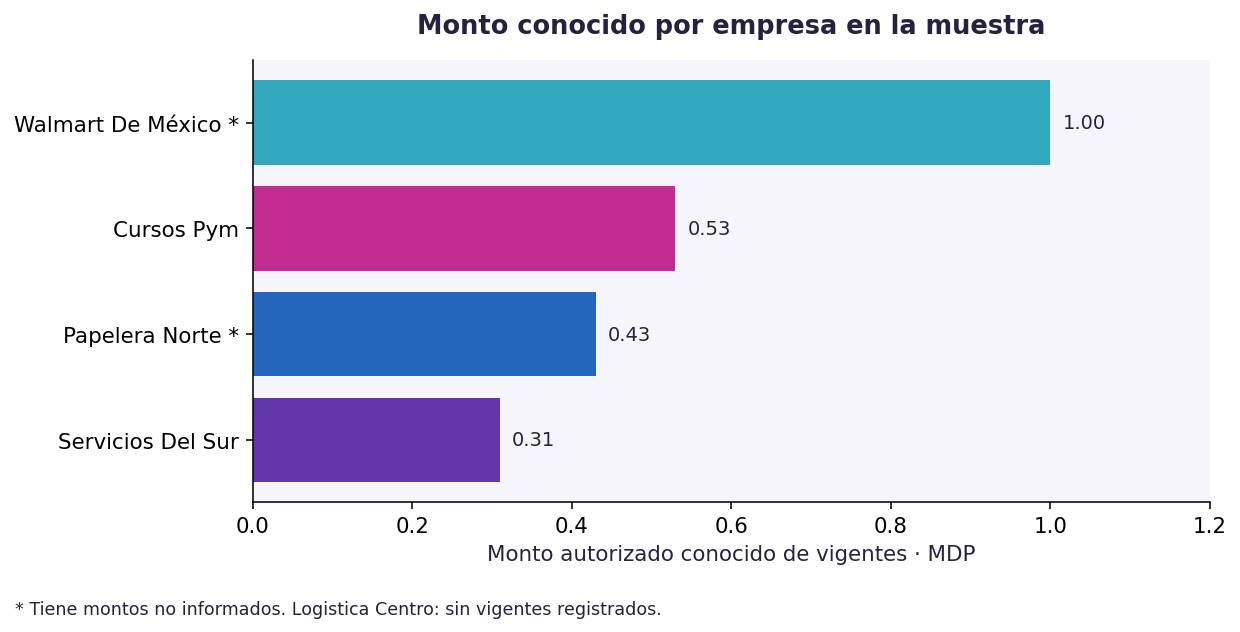

In [18]:
grafico_banca = banca_resumen[banca_resumen["CreditosVigentes"].notna()].copy()
grafico_banca = grafico_banca.sort_values("MontoConocidoMXN")
etiquetas = [
    fila.Empresa + (" *" if fila.CreditosVigentes > fila.MontosInformados else "")
    for fila in grafico_banca.itertuples()
]
fig, ax = plt.subplots(figsize=(9,4.5))
barras = ax.barh(etiquetas,grafico_banca["MontoConocidoMXN"]/1000000.0,
                 color=COLORES_PYM[:len(grafico_banca)])
for barra,monto in zip(barras,grafico_banca["MontoConocidoMXN"]):
    ax.text(barra.get_width()+0.015,barra.get_y()+barra.get_height()/2,
            "{:.2f}".format(monto/1000000),va="center",fontsize=10)
ax.set_xlim(0,1.20)
ax.set_xlabel("Monto autorizado conocido de vigentes · MDP")
ax.set_title("Monto conocido por empresa en la muestra",weight="bold",pad=14)
fig.text(0.02,0.01,"* Tiene montos no informados. Logistica Centro: sin vigentes registrados.",fontsize=9)
fig.tight_layout(rect=(0,0.05,1,1))
plt.show()


## 🚀 16. Dejamos evidencia de calidad
El control registra lo recibido, retirado y pendiente. Permite mostrar por qué cambió
una cifra sin reconstruir la jornada desde la memoria. Verificamos el original intacto.


In [19]:
banca_calidad = pd.DataFrame({
    "Control":["Filas recibidas","Duplicados exactos retirados","Creditos unicos preparados",
               "Creditos con monto faltante","Creditos con plazo faltante",
               "Vigentes Walmart sin monto","Empresas catalogadas","Empresas sin vigentes en muestra"],
    "Valor":[filas_recibidas,filas_recibidas-filas_sin_repeticion,
             df_creditos_limpio_banca.shape[0],
             df_creditos_limpio_banca["Monto_Autorizado_MXN"].isna().sum(),
             df_creditos_limpio_banca["Plazo_Meses"].isna().sum(),
             banca_sin_monto.shape[0],df_empresas.shape[0],sin_coincidencia.shape[0]]
})
display(banca_calidad)
pd.testing.assert_frame_equal(df_creditos_crudo_banca,original_banca)
assert df_creditos_limpio_banca["Monto_Autorizado_MXN"].isna().sum() == 2


,Control,Valor
0,Filas recibidas,14
1,Duplicados exactos retirados,1
2,Creditos unicos preparados,13
3,Creditos con monto faltante,2
4,Creditos con plazo faltante,3
5,Vigentes Walmart sin monto,1
6,Empresas catalogadas,5
7,Empresas sin vigentes en muestra,1


## 🤖 17. Pedimos apoyo a IA y comprobamos su sugerencia
Como en C3, entendemos la lógica antes de generalizarla. Esta plantilla es un ejemplo
resuelto: la libreta no llama a una API ni requiere credenciales. La respuesta ilustrativa
siguiente fue redactada para esta guía.

> Apoya a un analista jr. Tengo créditos únicos por Operacion y catálogo único por Empresa.
> Necesito conservar todo el catálogo al unir un resumen de vigentes. MontoAutorizado puede
> ser NULL. Explica dónde agregar, qué tabla conservar y tres controles. No inventes fecha,
> saldo ni riesgo. Distingue monto faltante de empresa sin coincidencia.

**Respuesta ilustrativa:** «Resume por Empresa antes de unir. Coloca el catálogo a la
izquierda de LEFT JOIN. Valida unicidad, cobertura completa y conciliación del monto
conocido con el control de vigentes». Vamos a comprobarlo con las salidas reales.


In [20]:
verificacion_ia = pd.DataFrame({
    "Regla":["Una fila por empresa","Se conserva el catálogo","El monto conocido concilia"],
    "Se cumple":[banca_resumen["Empresa"].is_unique,
                 set(banca_resumen["Empresa"]) == set(df_empresas["Empresa"]),
                 np.isclose(banca_resumen["MontoConocidoMXN"].sum(),
                            control_vigentes.loc[0,"MontoConocidoMXN"])]
})
display(verificacion_ia)
assert verificacion_ia["Se cumple"].all()


,Regla,Se cumple
0,Una fila por empresa,True
1,Se conserva el catálogo,True
2,El monto conocido concilia,True


## 🚀 18. Exportamos y volvemos a leer
Generamos detalle, resumen y control. index=False evita una columna adicional.
utf-8-sig facilita acentos en Excel. Volver a leer verifica el archivo que realmente
recibirá el área, incluidos registros, columnas y faltantes.


In [21]:
archivos_banca = {
    "banca_detalle_sql.csv":banca_detalle,
    "banca_resumen_empresas_sql.csv":banca_resumen,
    "banca_control_calidad.csv":banca_calidad
}
for nombre,tabla in archivos_banca.items():
    ruta = carpeta_salida/nombre
    tabla.to_csv(ruta,index=False,encoding="utf-8-sig")
    pd.testing.assert_frame_equal(tabla,pd.read_csv(ruta),check_dtype=False)
    print("Exportado y verificado:",nombre)
assert pd.read_csv(carpeta_salida/"banca_resumen_empresas_sql.csv")["MontoConocidoMXN"].isna().sum() == 1


Exportado y verificado: banca_detalle_sql.csv
Exportado y verificado: banca_resumen_empresas_sql.csv
Exportado y verificado: banca_control_calidad.csv


## 🔥 19. Comunicamos cifras, alcance y siguiente contacto
El mensaje usa variables del análisis y deja un pendiente concreto para contabilidad:
completar OP-005. Las tres frases permiten revisar el archivo y entender sus límites.


In [22]:
mensaje_finanzas = (
    "Se identificaron {} créditos vigentes de Walmart De México con monto autorizado "
    "conocido de al menos 250,000 MXN, por {:,.0f} MXN; queda {} vigente de Walmart "
    "sin monto informado (OP-005), pendiente de completar con contabilidad. "
    "El resumen conserva {} empresas y registra {:,.0f} MXN conocidos en {} vigentes con "
    "{} montos faltantes; Logistica Centro no presenta vigentes en la muestra. "
    "Son montos originalmente autorizados conocidos de un archivo sin fecha de corte informada: "
    "no permiten concluir saldo actual ni evaluar riesgo."
).format(int(banca_control.loc[0,"Creditos"]),float(banca_control.loc[0,"MontoConocidoMXN"]),
         banca_sin_monto.shape[0],banca_resumen.shape[0],float(control_vigentes.loc[0,"MontoConocidoMXN"]),
         int(control_vigentes.loc[0,"CreditosVigentes"]),
         int(control_vigentes.loc[0,"CreditosVigentes"]-control_vigentes.loc[0,"MontosInformados"]))
display(Markdown("**Mensaje para finanzas**\n\n"+mensaje_finanzas))
(carpeta_salida/"mensaje_finanzas.txt").write_text(mensaje_finanzas,encoding="utf-8")
import shutil
ruta_zip = shutil.make_archive(str(carpeta_trabajo/"entrega_banca"),"zip",carpeta_salida)
print("Paquete listo:",ruta_zip)
print("En Colab: panel Archivos → pym_banca → entrega_banca.zip → Descargar.")


**Mensaje para finanzas**

Se identificaron 3 créditos vigentes de Walmart De México con monto autorizado conocido de al menos 250,000 MXN, por 1,000,000 MXN; queda 1 vigente de Walmart sin monto informado (OP-005), pendiente de completar con contabilidad. El resumen conserva 5 empresas y registra 2,270,000 MXN conocidos en 10 vigentes con 2 montos faltantes; Logistica Centro no presenta vigentes en la muestra. Son montos originalmente autorizados conocidos de un archivo sin fecha de corte informada: no permiten concluir saldo actual ni evaluar riesgo.

Paquete listo: /workspace/scratch/a72119b51a6b/work/run_banca/pym_banca/entrega_banca.zip
En Colab: panel Archivos → pym_banca → entrega_banca.zip → Descargar.


## 🐼 20. Unimos las piezas del trabajo
| Etapa | Herramientas | Propósito laboral |
|---|---|---|
| Entender | Unidad, métrica y reglas | Separar detalle, prioridad y catálogo completo. |
| Diagnosticar | head, shape, info, faltantes | Reconocer el insumo antes de calcular. |
| Preparar | Copias, duplicados, cadenas, map, función | Conservar evidencia y empresas comparables. |
| Consultar | SELECT, WHERE, orden, agregados, GROUP BY, HAVING | Responder al nivel solicitado. |
| Relacionar | Subconsulta, LEFT e INNER JOIN | Conservar cobertura y explicar empresas sin actividad. |
| Validar | Comparación pandas–SQL, conteos y conciliación | Sostener cifras y alcance. |
| Entregar | CSV revisados y mensaje breve | Facilitar revisión y seguimiento con contabilidad. |

**Lo que consolidó el proyecto bancario:** nombres diferentes pueden fragmentar un reporte,
una fila repetida puede inflar importes y una unión puede ocultar empresas aunque la suma
coincida. El trabajo del analista jr incluye detectar esas situaciones, decidir con reglas
y explicar lo que entrega.

**Ante otro archivo bajo el mismo contrato**, la función y las consultas ya son reutilizables.
Cargaríamos el nuevo insumo, revisaríamos llaves y faltantes, reconstruiríamos las tablas de
práctica y contrastaríamos resultados con ese corte. Los controles numéricos de esta guía
describen la muestra original; no hay que modificar datos para que pasen con un corte nuevo.

**Base didáctica:** Casos_de_uso_C3 (1).ipynb (flujo, funciones e IA),
Copia_de_Tarea_2_intermedio_202610 (2)(1).ipynb (consignas originales de banca)
y Tarea_3_SQL_Contexto_Laboral_PyM.ipynb (mismos créditos y catálogo). Se distinguieron
las respuestas añadidas por el estudiante de las reglas originales.

🚀 Recibimos un archivo y entregamos información revisable, alcance y un pendiente trazable.
